In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from frag_gnn.runner import load_config, init_dataset, init_dataloader
from frag_gnn.pl_model import FragGNNPL
from frag_gnn.dataset import SpecMolFragDataset
from frag_gnn.utils.misc_utils import scatter_reduce, scatter_argmax, scatter_argtopk, EPS, booltype, scatter_masked_softmax, scatter_logsumexp, safelog, LOG_ZERO
from frag_gnn.utils.script_utils import init_wandb_ckpt, run_inference, select_model_vals, sparse_kl, log_mean, log_std, pearson_r
from frag_gnn.loss import sparse_conditional_entropy_fn, sparse_cosine_distance_hungarian

import numpy as np
import torch as th
import pandas as pd
import argparse	
import wandb
import os
from pprint import pprint

In [3]:
baseline_vals_fp = "../inference_outputs/entropyv3/scaffold_d3_baseline_test_False/vals.pkl"
baseline_vals = th.load(baseline_vals_fp)

In [4]:
low_vals_fp = "../inference_outputs/entropyv3/scaffold_d3_posfn_test_False/vals.pkl"
low_vals = th.load(low_vals_fp)

In [5]:
high_vals_fp = "../inference_outputs/entropyv3/scaffold_d3_negfn_test_False/vals.pkl"
high_vals = th.load(high_vals_fp)

In [6]:
mix_vals_fp = "../inference_outputs/entropyv3/scaffold_d3_mix_test_False/vals.pkl"
mix_vals = th.load(mix_vals_fp)

In [7]:
debug_vals = mix_vals["entropyv3_scaffold_d3_baseline_ens_s00"]
print(debug_vals["pred_nb_joint_formula_idxs"].max(), debug_vals["pred_nb_joint_formula_idxs"].unique().shape)
# print(debug_vals["pred_formula_idxs"].max(), debug_vals["pred_formula_idxs"].unique().shape)
print(debug_vals["pred_batch_idxs"].max(), debug_vals["pred_batch_idxs"].unique().shape)

# note: each spectrum has a NULL formula at (local) index 0
# this means that the number of 

tensor(2356021) torch.Size([2352681])
tensor(3340) torch.Size([3341])


In [8]:
def ensemble_vals(vals, nb=True, spec=False, ens_conds=False):

    select_keys = [
        "pred_formula_logprobs",
        "pred_formula_batch_idxs",
        "pred_formula_formula_idxs",
    ]
    if spec:
        select_keys += [
            "pred_mzs",
            "pred_logprobs",
            "pred_batch_idxs",
            "true_mzs",
            "true_logprobs",
            "true_batch_idxs",
        ]

    if nb:
        select_keys += [
            "pred_nb_joint_logprobs",
            "pred_nb_formula_node_logprobs",
            "pred_nb_joint_formula_idxs",
            "pred_nb_joint_batch_idxs",
            "pred_nb_joint_node_idxs"
        ]
    else:
        select_keys += [
            "pred_joint_logprobs",
            "pred_formula_node_logprobs",
            "pred_joint_formula_idxs",
            "pred_joint_batch_idxs",
            "pred_joint_node_idxs",
        ]

    select_d = select_model_vals(vals,select_keys,stack_dim=0)
    # formula stuff
    ens_formula_logprobs = log_mean(select_d["pred_formula_logprobs"],dim=0)
    ens_formula_batch_idxs = select_d["pred_formula_batch_idxs"][0]
    ens_formula_formula_idxs = select_d["pred_formula_formula_idxs"][0]
    
    ens_d = {
        "ens_formula_logprobs": ens_formula_logprobs,
        "ens_formula_batch_idxs": ens_formula_batch_idxs,
        "ens_formula_formula_idxs": ens_formula_formula_idxs,
    }
    
    if spec:

        ens_pred_logprobs = log_mean(select_d["pred_logprobs"],dim=0)
        ens_pred_mzs = select_d["pred_mzs"][0]
        ens_pred_batch_idxs = select_d["pred_batch_idxs"][0]
        ens_true_logprobs = select_d["true_logprobs"][0]
        ens_true_mzs = select_d["true_mzs"][0]
        ens_true_batch_idxs = select_d["true_batch_idxs"][0]
        ens_d.update({
            "ens_pred_logprobs": ens_pred_logprobs,
            "ens_pred_mzs": ens_pred_mzs,
            "ens_pred_batch_idxs": ens_pred_batch_idxs,
            "ens_true_logprobs": ens_true_logprobs,
            "ens_true_mzs": ens_true_mzs,
            "ens_true_batch_idxs": ens_true_batch_idxs
        })

    if nb:
        
        # non-iso joint stuff
        ens_nb_joint_formula_idxs = select_d["pred_nb_joint_formula_idxs"][0]
        ens_nb_joint_batch_idxs = select_d["pred_nb_joint_batch_idxs"][0]
        ens_nb_joint_node_idxs = select_d["pred_nb_joint_node_idxs"][0]
        if ens_conds:
            ens_nb_formula_node_logprobs = log_mean(select_d["pred_nb_formula_node_logprobs"],dim=0)
            ens_nb_joint_logprobs = ens_nb_formula_node_logprobs + ens_formula_logprobs[ens_nb_joint_formula_idxs]
        else:
            ens_nb_joint_logprobs = log_mean(select_d["pred_nb_joint_logprobs"],dim=0)
            ens_nb_formula_node_logprobs = ens_nb_joint_logprobs - ens_formula_logprobs[ens_nb_joint_formula_idxs]
            ens_nb_formula_node_logprobs = th.clamp(ens_nb_formula_node_logprobs, max=0.)
        ens_nb_formula_node_lse = scatter_logsumexp(ens_nb_formula_node_logprobs, ens_nb_joint_formula_idxs, dim_size=ens_formula_formula_idxs.shape[0])
    
        ens_d.update({
            "ens_nb_joint_logprobs": ens_nb_joint_logprobs,
            "ens_nb_joint_formula_idxs": ens_nb_joint_formula_idxs,
            "ens_nb_joint_batch_idxs": ens_nb_joint_batch_idxs,
            "ens_nb_joint_node_idxs": ens_nb_joint_node_idxs,
            "ens_nb_formula_node_logprobs": ens_nb_formula_node_logprobs,
            "ens_nb_formula_node_lse": ens_nb_formula_node_lse
        })

    else:

        # iso joint stuff
        ens_joint_formula_idxs = select_d["pred_joint_formula_idxs"][0]
        ens_joint_batch_idxs = select_d["pred_joint_batch_idxs"][0]
        ens_joint_node_idxs = select_d["pred_joint_node_idxs"][0]
        if ens_conds:
            ens_formula_node_logprobs = log_mean(select_d["pred_formula_node_logprobs"],dim=0)
            ens_joint_logprobs = ens_formula_node_logprobs + ens_formula_logprobs[ens_joint_formula_idxs]
        else:
            ens_joint_logprobs = log_mean(select_d["pred_joint_logprobs"],dim=0)
            ens_formula_node_logprobs = ens_joint_logprobs - ens_formula_logprobs[ens_joint_formula_idxs]
            ens_formula_node_logprobs = th.clamp(ens_formula_node_logprobs, max=0.)
        ens_formula_node_lse = scatter_logsumexp(ens_formula_node_logprobs, ens_joint_formula_idxs, dim_size=ens_formula_formula_idxs.shape[0])
    
        ens_d.update({
            "ens_joint_logprobs": ens_joint_logprobs,
            "ens_joint_formula_idxs": ens_joint_formula_idxs,
            "ens_joint_batch_idxs": ens_joint_batch_idxs,
            "ens_joint_node_idxs": ens_joint_node_idxs,
            "ens_formula_node_logprobs": ens_formula_node_logprobs,
            "ens_formula_node_lse": ens_formula_node_lse,
        })
    
    return ens_d

In [9]:
def get_topk_formula_node_idxs(ens_vals, k, nb=True, filter_thresh=0.01):

    ens_formula_logprobs = ens_vals["ens_formula_logprobs"]
    ens_formula_mask = ens_formula_logprobs > np.log(filter_thresh)

    if nb:
        prefix = "nb_"
    else:
        prefix = ""

    ens_counts = scatter_reduce(
        src=th.ones_like(ens_vals[f"ens_{prefix}formula_node_logprobs"], dtype=th.long),
        index=ens_vals[f"ens_{prefix}joint_formula_idxs"],
        reduce="sum",
        dim_size=th.max(ens_vals[f"ens_{prefix}joint_formula_idxs"])+1
    )

    ens_nb_formula_node_argtopk = scatter_argtopk(
        ens_vals[f"ens_{prefix}formula_node_logprobs"],
        ens_vals[f"ens_{prefix}joint_formula_idxs"],
        ens_vals[f"ens_{prefix}joint_node_idxs"],
        k,
        dim_size=ens_formula_mask.shape[0],
        return_max=False
    )

    return ens_formula_mask, ens_counts, ens_nb_formula_node_argtopk

In [10]:
def calculate_compare(masks, argtopks):

    num_ens = len(masks)
    compare_mat = th.zeros((num_ens,num_ens),dtype=th.float32)

    for i in range(num_ens):
        for j in range(num_ens):
            mask_i = masks[i]
            mask_j = masks[j]
            argtopk_i = argtopks[i]
            argtopk_j = argtopks[j]
            mask_ij = mask_i & mask_j
            equal_ij = th.all(argtopk_i[mask_ij] == argtopk_j[mask_ij], dim=1)
            compare_mat[i,j] = equal_ij.float().mean()

    # everything
    mask_all = th.stack(masks, dim=0).all(dim=0)
    # print("1:", all_mask.shape, all_mask.float().mean())
    argtopks_all = th.stack(argtopks, dim=0)
    # print("2:", all_argtopks.shape)
    equal_all = (argtopks_all == argtopks[0].unsqueeze(0))
    # print("3:", all_equal.shape)
    equal_all = equal_all.all(2).all(0)
    equal_all[~mask_all] = False
    # print("4:", all_equal.shape)
    compare_all = equal_all.float().mean()

    return compare_mat, compare_all, equal_all

In [11]:
k = 1

# Non-Isomorphic Joint

In [ ]:
baseline_nb_ens_vals = ensemble_vals(baseline_vals, nb=True)
low_nb_ens_vals = ensemble_vals(low_vals, nb=True)
high_nb_ens_vals = ensemble_vals(high_vals, nb=True)
mix_nb_ens_vals = ensemble_vals(mix_vals, nb=True, spec=True)

In [29]:
print("> baseline")
baseline_nb_mask, baseline_nb_counts, baseline_nb_argtopk = get_topk_formula_node_idxs(baseline_nb_ens_vals, k, nb=True)
print(th.unique(baseline_nb_counts[baseline_nb_mask], return_counts=True)[1][:10])
print((baseline_nb_counts[baseline_nb_mask] < k).float().mean())
print((baseline_nb_argtopk[baseline_nb_mask] == -1).any(dim=1).float().mean())

print("> low")
low_nb_mask, low_nb_counts, low_nb_argtopk = get_topk_formula_node_idxs(low_nb_ens_vals, k, nb=True)
print(th.unique(low_nb_counts[low_nb_mask], return_counts=True)[1][:10])
print((low_nb_counts[low_nb_mask] < k).float().mean())
print((low_nb_argtopk[low_nb_mask] == -1).any(dim=1).float().mean())

print("> high")
high_nb_mask, high_nb_counts, high_nb_argtopk = get_topk_formula_node_idxs(high_nb_ens_vals, k, nb=True)
print(th.unique(high_nb_counts[high_nb_mask], return_counts=True)[1][:10])
print((high_nb_counts[high_nb_mask] < k).float().mean())
print((high_nb_argtopk[high_nb_mask] == -1).any(dim=1).float().mean())

print("> mix")
mix_nb_mask, mix_nb_counts, mix_nb_argtopk = get_topk_formula_node_idxs(mix_nb_ens_vals, k, nb=True)
print(th.unique(mix_nb_counts[mix_nb_mask], return_counts=True)[1][:10])
print((mix_nb_counts[mix_nb_mask] < k).float().mean())
print((mix_nb_argtopk[mix_nb_mask] == -1).any(dim=1).float().mean())

> baseline
tensor([28960,  9693,  5543,  3189,  1873,  1386,   838,   618,   473,   351])
tensor(0.)
tensor(0.)
> low
tensor([28860,  9538,  5342,  3113,  1838,  1346,   850,   635,   466,   348])
tensor(0.)
tensor(0.)
> high
tensor([28889,  9680,  5597,  3306,  1868,  1375,   881,   639,   487,   356])
tensor(0.)
tensor(0.)
> mix
tensor([28782,  9562,  5490,  3190,  1853,  1355,   840,   620,   484,   350])
tensor(0.)
tensor(0.)


In [30]:
print("> compare (including singletons)")
compare_mat, compare_all, equal_all = calculate_compare(
    [baseline_nb_mask, low_nb_mask, high_nb_mask, mix_nb_mask],
    [baseline_nb_argtopk, low_nb_argtopk, high_nb_argtopk, mix_nb_argtopk]
)
print(compare_mat)
print(compare_all)

> compare (including singletons)
tensor([[1.0000, 0.9703, 0.9669, 0.9779],
        [0.9703, 1.0000, 0.9604, 0.9766],
        [0.9669, 0.9604, 1.0000, 0.9695],
        [0.9779, 0.9766, 0.9695, 1.0000]])
tensor(0.0188)


In [ ]:
baseline_nb_c_mask = baseline_nb_mask & (baseline_nb_counts > k)
low_nb_c_mask = low_nb_mask & (low_nb_counts > k)
high_nb_c_mask = high_nb_mask & (high_nb_counts > k)
mix_nb_c_mask = mix_nb_mask & (mix_nb_counts > k)
print(baseline_nb_mask.float().mean(), baseline_nb_c_mask.float().mean())
print(low_nb_mask.float().mean(), low_nb_c_mask.float().mean())
print(high_nb_mask.float().mean(), high_nb_c_mask.float().mean())
print(mix_nb_mask.float().mean(), mix_nb_c_mask.float().mean())

tensor(0.0232) tensor(0.0109)
tensor(0.0230) tensor(0.0107)
tensor(0.0232) tensor(0.0110)
tensor(0.0230) tensor(0.0108)


In [32]:
print("> compare (excluding singletons)")
compare_mat, compare_all, equal_all = calculate_compare(
    [baseline_nb_c_mask, low_nb_c_mask, high_nb_c_mask, mix_nb_c_mask],
    [baseline_nb_argtopk, low_nb_argtopk, high_nb_argtopk, mix_nb_argtopk]
)
print(compare_mat)
print(compare_all)

> compare (excluding singletons)
tensor([[1.0000, 0.9359, 0.9289, 0.9526],
        [0.9359, 1.0000, 0.9143, 0.9496],
        [0.9289, 0.9143, 1.0000, 0.9344],
        [0.9526, 0.9496, 0.9344, 1.0000]])
tensor(0.0081)


In [ ]:
ens_cos_hun = 1. - sparse_cosine_distance_hungarian(
    mix_nb_ens_vals["ens_true_mzs"],
    mix_nb_ens_vals["ens_true_logprobs"],
    mix_nb_ens_vals["ens_true_batch_idxs"],
    mix_nb_ens_vals["ens_pred_mzs"],
    mix_nb_ens_vals["ens_pred_logprobs"],
    mix_nb_ens_vals["ens_pred_batch_idxs"],
)
print(ens_cos_hun.mean())

tensor(0.6530)


In [ ]:
ens_formula_batch_idxs = mix_nb_ens_vals["ens_formula_batch_idxs"].clone()
ens_formula_logprobs = mix_nb_ens_vals["ens_formula_logprobs"].clone()

sum_logprobs = scatter_logsumexp(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1
)

print(sum_logprobs.exp().min(), sum_logprobs.exp().max())

max_logprobs = scatter_reduce(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1,
    reduce="amax",
    default=LOG_ZERO(th.float32)
)

print(max_logprobs.exp().min(), max_logprobs.exp().max())

tensor(1.0000) tensor(1.0000)
tensor(0.0297) tensor(0.7821)


In [ ]:
mix_nb_ens_formula_batch_idxs = mix_nb_ens_vals["ens_formula_batch_idxs"].clone()
mix_nb_ens_formula_logprobs = mix_nb_ens_vals["ens_formula_logprobs"].clone()
mix_nb_ens_formula_logprobs[~equal_all] = LOG_ZERO(th.float32)

print("> unequal mean")

unequal_mean_logprobs = scatter_logsumexp(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1
)

print(unequal_mean_logprobs.shape)
print(unequal_mean_logprobs.exp().mean(), unequal_mean_logprobs.exp().min(), unequal_mean_logprobs.exp().max())
print(pearson_r(unequal_mean_logprobs.exp(), ens_cos_hun))
for i in [0.01, 0.02, 0.05, 0.1, 0.15, 0.2]:
    print(
        i, 
        (unequal_mean_logprobs.exp() >= i).float().mean(), 
        ens_cos_hun[unequal_mean_logprobs.exp() >= i].mean(), 
        ens_cos_hun[unequal_mean_logprobs.exp() < i].mean(),
    )


# print(mix_nb_counts.min(), mix_nb_counts.max())

# ens_mean_counts = scatter_reduce(
#     mix_nb_counts.float()[mix_nb_counts>0],
#     ens_formula_batch_idxs[mix_nb_counts>0],
#     reduce="mean",
#     dim_size=th.max(ens_formula_batch_idxs)+1,
#     include_self=False
# )

# print(ens_mean_counts.shape)
# print(ens_mean_counts.mean(), ens_mean_counts.min(), ens_mean_counts.max())
# print(pearson_r(ens_mean_counts, ens_cos_hun))
# for i in range(1,5+1):
#     print(i, ens_cos_hun[ens_mean_counts >= i].mean(), ens_cos_hun[ens_mean_counts < i].mean())

> unequal mean
torch.Size([3341])
tensor(0.2541) tensor(0.) tensor(0.8617)
tensor(0.0424)
0.01 tensor(0.9392) tensor(0.6497) tensor(0.7045)
0.02 tensor(0.9204) tensor(0.6484) tensor(0.7072)
0.05 tensor(0.8593) tensor(0.6437) tensor(0.7099)
0.1 tensor(0.7722) tensor(0.6418) tensor(0.6911)
0.15 tensor(0.6851) tensor(0.6441) tensor(0.6726)
0.2 tensor(0.5831) tensor(0.6455) tensor(0.6635)


In [222]:
print("> unequal max")

ens_formula_logprobs = mix_nb_ens_vals["ens_formula_logprobs"].clone()
ens_formula_logprobs[equal_all] = LOG_ZERO(th.float32)

unequal_max_logprobs = scatter_reduce(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1,
    reduce="amax",
    default=LOG_ZERO(th.float32)
)

print(unequal_max_logprobs.shape)
print(unequal_max_logprobs.exp().mean(), unequal_max_logprobs.exp().min(), unequal_max_logprobs.exp().max())
print(pearson_r(unequal_max_logprobs.exp(), ens_cos_hun))
for i in [0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    print(
        i, 
        (unequal_max_logprobs.exp() >= i).float().mean(), 
        ens_cos_hun[unequal_max_logprobs.exp() >= i].mean(), 
        ens_cos_hun[unequal_max_logprobs.exp() < i].mean()
    )

> unequal max
torch.Size([3341])
tensor(0.1912) tensor(0.0165) tensor(0.7821)
tensor(0.3779)
0.01 tensor(1.) tensor(0.6530) tensor(nan)
0.1 tensor(0.7719) tensor(0.6788) tensor(0.5657)
0.2 tensor(0.3607) tensor(0.7407) tensor(0.6036)
0.3 tensor(0.1616) tensor(0.7845) tensor(0.6277)
0.4 tensor(0.0712) tensor(0.8311) tensor(0.6394)
0.5 tensor(0.0290) tensor(0.8629) tensor(0.6468)
0.6 tensor(0.0090) tensor(0.8889) tensor(0.6509)
0.7 tensor(0.0015) tensor(0.8287) tensor(0.6528)


# Non-Isomorphic Conditional

In [ ]:
baseline_nbc_ens_vals = ensemble_vals(baseline_vals, nb=True, ens_conds=True)
low_nbc_ens_vals = ensemble_vals(low_vals, nb=True, ens_conds=True)
high_nbc_ens_vals = ensemble_vals(high_vals, nb=True, ens_conds=True)
mix_nbc_ens_vals = ensemble_vals(mix_vals, nb=True, ens_conds=True, spec=True)

In [37]:
print("> baseline")
baseline_nbc_mask, baseline_nbc_counts, baseline_nbc_argtopk = get_topk_formula_node_idxs(baseline_nbc_ens_vals, k, nb=True)
print(th.unique(baseline_nbc_counts[baseline_nbc_mask], return_counts=True)[1][:10])
print((baseline_nbc_counts[baseline_nbc_mask] < k).float().mean())
print((baseline_nbc_argtopk[baseline_nbc_mask] == -1).any(dim=1).float().mean())

print("> low")
low_nbc_mask, low_nbc_counts, low_nbc_argtopk = get_topk_formula_node_idxs(low_nbc_ens_vals, k, nb=True)
print(th.unique(low_nbc_counts[low_nbc_mask], return_counts=True)[1][:10])
print((low_nbc_counts[low_nbc_mask] < k).float().mean())
print((low_nbc_argtopk[low_nbc_mask] == -1).any(dim=1).float().mean())

print("> high")
high_nbc_mask, high_nbc_counts, high_nbc_argtopk = get_topk_formula_node_idxs(high_nbc_ens_vals, k, nb=True)
print(th.unique(high_nbc_counts[high_nbc_mask], return_counts=True)[1][:10])
print((high_nbc_counts[high_nbc_mask] < k).float().mean())
print((high_nbc_argtopk[high_nbc_mask] == -1).any(dim=1).float().mean())

print("> mix")
mix_nbc_mask, mix_nbc_counts, mix_nbc_argtopk = get_topk_formula_node_idxs(mix_nbc_ens_vals, k, nb=True)
print(th.unique(mix_nbc_counts[mix_nbc_mask], return_counts=True)[1][:10])
print((mix_nbc_counts[mix_nbc_mask] < k).float().mean())
print((mix_nbc_argtopk[mix_nbc_mask] == -1).any(dim=1).float().mean())

> baseline
tensor([28960,  9693,  5543,  3189,  1873,  1386,   838,   618,   473,   351])
tensor(0.)
tensor(0.)
> low
tensor([28860,  9538,  5342,  3113,  1838,  1346,   850,   635,   466,   348])
tensor(0.)
tensor(0.)
> high
tensor([28889,  9680,  5597,  3306,  1868,  1375,   881,   639,   487,   356])
tensor(0.)
tensor(0.)
> mix
tensor([28782,  9562,  5490,  3190,  1853,  1355,   840,   620,   484,   350])
tensor(0.)
tensor(0.)


In [38]:
baseline_nbc_c_mask = baseline_nbc_mask & (baseline_nbc_counts > k)
low_nbc_c_mask = low_nbc_mask & (low_nbc_counts > k)
high_nbc_c_mask = high_nbc_mask & (high_nbc_counts > k)
mix_nbc_c_mask = mix_nbc_mask & (mix_nbc_counts > k)
print(baseline_nbc_mask.float().mean(), baseline_nbc_c_mask.float().mean())
print(low_nbc_mask.float().mean(), low_nbc_c_mask.float().mean())
print(high_nbc_mask.float().mean(), high_nbc_c_mask.float().mean())
print(mix_nbc_mask.float().mean(), mix_nbc_c_mask.float().mean())

tensor(0.0232) tensor(0.0109)
tensor(0.0230) tensor(0.0107)
tensor(0.0232) tensor(0.0110)
tensor(0.0230) tensor(0.0108)


In [41]:
print("> compare (excluding singletons)")
compare_mat, compare_all, equal_all = calculate_compare(
    [baseline_nbc_c_mask, low_nbc_c_mask, high_nbc_c_mask, mix_nbc_c_mask],
    [baseline_nbc_argtopk, low_nbc_argtopk, high_nbc_argtopk, mix_nbc_argtopk]
)
print(compare_mat)
print(compare_all)

> compare (excluding singletons)
tensor([[1.0000, 0.9390, 0.9352, 0.9545],
        [0.9390, 1.0000, 0.9184, 0.9534],
        [0.9352, 0.9184, 1.0000, 0.9359],
        [0.9545, 0.9534, 0.9359, 1.0000]])
tensor(0.0082)


In [43]:
mix_nbc_ens_cos_hun = 1. - sparse_cosine_distance_hungarian(
    mix_nbc_ens_vals["ens_true_mzs"],
    mix_nbc_ens_vals["ens_true_logprobs"],
    mix_nbc_ens_vals["ens_true_batch_idxs"],
    mix_nbc_ens_vals["ens_pred_mzs"],
    mix_nbc_ens_vals["ens_pred_logprobs"],
    mix_nbc_ens_vals["ens_pred_batch_idxs"],
)
print(mix_nbc_ens_cos_hun.mean())

tensor(0.6530)


# Isomorphic

In [54]:
baseline_ens_vals = ensemble_vals(baseline_vals, nb=False)
low_ens_vals = ensemble_vals(low_vals, nb=False)
high_ens_vals = ensemble_vals(high_vals, nb=False)
mix_ens_vals = ensemble_vals(mix_vals, nb=False)

In [55]:
print("> baseline")
baseline_mask, baseline_counts, baseline_argtopk = get_topk_formula_node_idxs(baseline_ens_vals, k, nb=False)
print(th.unique(baseline_counts[baseline_mask], return_counts=True)[1][:10])
print((baseline_counts[baseline_mask] < k).float().mean())
print((baseline_argtopk[baseline_mask] == -1).any(dim=1).float().mean())

print("> low")
low_mask, low_counts, low_argtopk = get_topk_formula_node_idxs(low_ens_vals, k, nb=False)
print(th.unique(low_counts[low_mask], return_counts=True)[1][:10])
print((low_counts[low_mask] < k).float().mean())
print((low_argtopk[low_mask] == -1).any(dim=1).float().mean())

print("> high")
high_mask, high_counts, high_argtopk = get_topk_formula_node_idxs(high_ens_vals, k, nb=False)
print(th.unique(high_counts[high_mask], return_counts=True)[1][:10])
print((high_counts[high_mask] < k).float().mean())
print((high_argtopk[high_mask] == -1).any(dim=1).float().mean())

print("> mix")
mix_mask, mix_counts, mix_argtopk = get_topk_formula_node_idxs(mix_ens_vals, k, nb=False)
print(th.unique(mix_counts[mix_mask], return_counts=True)[1][:10])
print((mix_counts[mix_mask] < k).float().mean())
print((mix_argtopk[mix_mask] == -1).any(dim=1).float().mean())

> baseline
tensor([18436, 11224,  5986,  4688,  2891,  2808,  1660,  1528,   921,  1034])
tensor(0.)
tensor(0.)
> low
tensor([18587, 11058,  5851,  4536,  2817,  2675,  1639,  1479,   893,  1034])
tensor(0.)
tensor(0.)
> high
tensor([18045, 11235,  6042,  4809,  2959,  2860,  1688,  1595,   952,  1041])
tensor(0.)
tensor(0.)
> mix
tensor([18257, 11099,  5960,  4667,  2896,  2770,  1641,  1517,   912,  1042])
tensor(0.)
tensor(0.)


In [56]:
print("> compare (including singletons)")
compare_mat, compare_all, equal_all = calculate_compare(
    [baseline_mask, low_mask, high_mask, mix_mask],
    [baseline_argtopk, low_argtopk, high_argtopk, mix_argtopk]
)
print(compare_mat)
print(compare_all)

> compare (including singletons)
tensor([[1.0000, 0.8968, 0.8985, 0.9128],
        [0.8968, 1.0000, 0.8786, 0.9179],
        [0.8985, 0.8786, 1.0000, 0.8970],
        [0.9128, 0.9179, 0.8970, 1.0000]])
tensor(0.0166)


In [57]:
baseline_c_mask = baseline_mask & (baseline_counts > k)
low_c_mask = low_mask & (low_counts > k)
high_c_mask = high_mask & (high_counts > k)
mix_c_mask = mix_mask & (mix_counts > k)
print(baseline_mask.float().mean(), baseline_c_mask.float().mean())
print(low_mask.float().mean(), low_c_mask.float().mean())
print(high_mask.float().mean(), high_c_mask.float().mean())
print(mix_mask.float().mean(), mix_c_mask.float().mean())

tensor(0.0232) tensor(0.0154)
tensor(0.0230) tensor(0.0151)
tensor(0.0232) tensor(0.0156)
tensor(0.0230) tensor(0.0153)


In [63]:
print("> compare (excluding singletons)")
compare_mat, compare_all, equal_all = calculate_compare(
    [baseline_c_mask, low_c_mask, high_c_mask, mix_c_mask],
    [baseline_argtopk, low_argtopk, high_argtopk, mix_argtopk]
)
print(compare_mat)
print(compare_all)

> compare (excluding singletons)
tensor([[1.0000, 0.8422, 0.8464, 0.8677],
        [0.8422, 1.0000, 0.8145, 0.8747],
        [0.8464, 0.8145, 1.0000, 0.8444],
        [0.8677, 0.8747, 0.8444, 1.0000]])
tensor(0.0097)


In [59]:
ens_cos_hun = 1. - sparse_cosine_distance_hungarian(
    mix_nb_ens_vals["ens_true_mzs"],
    mix_nb_ens_vals["ens_true_logprobs"],
    mix_nb_ens_vals["ens_true_batch_idxs"],
    mix_nb_ens_vals["ens_pred_mzs"],
    mix_nb_ens_vals["ens_pred_logprobs"],
    mix_nb_ens_vals["ens_pred_batch_idxs"],
)
print(ens_cos_hun.mean())

tensor(0.6530)


In [60]:
ens_formula_batch_idxs = mix_nb_ens_vals["ens_formula_batch_idxs"].clone()
ens_formula_logprobs = mix_nb_ens_vals["ens_formula_logprobs"].clone()

sum_logprobs = scatter_logsumexp(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1
)

print(sum_logprobs.exp().min(), sum_logprobs.exp().max())

max_logprobs = scatter_reduce(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1,
    reduce="amax",
    default=LOG_ZERO(th.float32)
)

print(max_logprobs.exp().min(), max_logprobs.exp().max())

tensor(1.0000) tensor(1.0000)
tensor(0.0297) tensor(0.7821)


In [73]:
import matplotlib.pyplot as plt
from scipy.stats import linregress

def scatter_with_fit(
        tensor_x, 
        tensor_y, 
        title="Scatterplot with Line of Best Fit",
        label_x="Tensor X",
        label_y="Tensor Y"
    ):
    """
    Creates a scatterplot for two PyTorch tensors, adds a line of best fit, and displays the Pearson correlation coefficient.

    Args:
        tensor_x (torch.Tensor): The first tensor (x-axis values).
        tensor_y (torch.Tensor): The second tensor (y-axis values).
        title (str): Title of the plot.

    Returns:
        None: Displays the plot.
    """
    # Ensure tensors are flattened and converted to NumPy arrays for plotting
    x = tensor_x.flatten().numpy()
    y = tensor_y.flatten().numpy()

    # Calculate Pearson correlation coefficient and line of best fit
    slope, intercept, r_value, _, _ = linregress(x, y)
    line = slope * x + intercept

    # Create the scatterplot
    plt.figure(figsize=(8, 6))
    plt.scatter(x, y, label="Data Points", alpha=0.7)
    plt.plot(x, line, color="red", label=f"Best Fit Line (r = {r_value:.2f})")
    
    # Add labels, title, and legend
    plt.xlabel(label_x)
    plt.ylabel(label_y)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    
    # Show the plot
    plt.show()

In [78]:
ens_formula_batch_idxs = mix_nb_ens_vals["ens_formula_batch_idxs"].clone()
ens_formula_logprobs = mix_nb_ens_vals["ens_formula_logprobs"].clone()
ens_formula_logprobs[~equal_all] = LOG_ZERO(th.float32)

print("> unequal mean")

unequal_mean_logprobs = scatter_logsumexp(
    ens_formula_logprobs,
    ens_formula_batch_idxs,
    dim_size=th.max(ens_formula_batch_idxs)+1
)

print(unequal_mean_logprobs.shape)
print(unequal_mean_logprobs.exp().mean(), unequal_mean_logprobs.exp().min(), unequal_mean_logprobs.exp().max())
print(pearson_r(unequal_mean_logprobs.exp(), ens_cos_hun))
for i in [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    print(
        i, 
        (unequal_mean_logprobs.exp() >= i).float().mean(), 
        ens_cos_hun[unequal_mean_logprobs.exp() >= i].mean(), 
        ens_cos_hun[unequal_mean_logprobs.exp() < i].mean(),
    )

> unequal mean
torch.Size([3341])
tensor(0.3096) tensor(0.) tensor(0.9530)
tensor(0.1024)
0.01 tensor(0.9779) tensor(0.6508) tensor(0.7502)
0.02 tensor(0.9638) tensor(0.6500) tensor(0.7345)
0.05 tensor(0.9312) tensor(0.6466) tensor(0.7404)
0.1 tensor(0.8635) tensor(0.6461) tensor(0.6967)
0.15 tensor(0.7914) tensor(0.6469) tensor(0.6763)
0.2 tensor(0.7067) tensor(0.6516) tensor(0.6565)
0.25 tensor(0.6037) tensor(0.6599) tensor(0.6426)
0.3 tensor(0.4981) tensor(0.6695) tensor(0.6367)
0.35 tensor(0.4077) tensor(0.6820) tensor(0.6331)
0.4 tensor(0.3161) tensor(0.7024) tensor(0.6302)
0.45 tensor(0.2260) tensor(0.7161) tensor(0.6346)
0.5 tensor(0.1529) tensor(0.7383) tensor(0.6377)


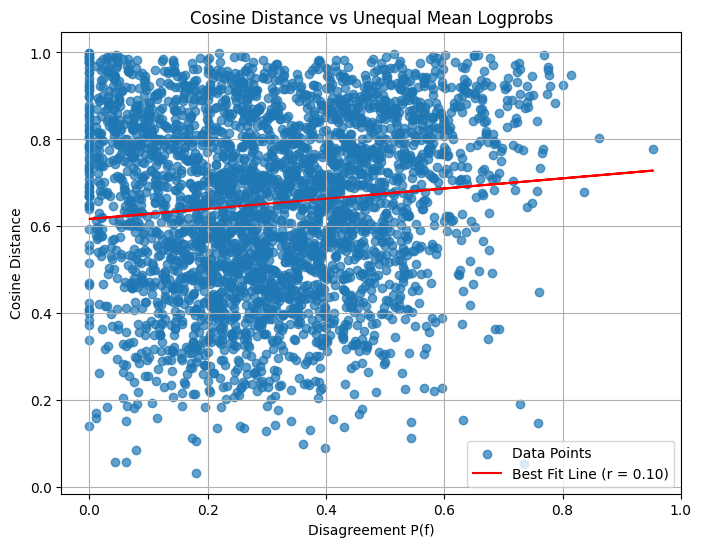

In [77]:
scatter_with_fit(
    unequal_mean_logprobs.exp(), 
    ens_cos_hun, 
    title="Cosine Distance vs Unequal Mean Logprobs",
    label_x="Disagreement P(f)",
    label_y="Cosine Distance"
)